In [1]:

from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

PROJECT_ROOT = Path(r"D:\FraudShield")
DATA_FILE = PROJECT_ROOT / "data" / "processed" / "train_merged.parquet"
MODEL_FILE = PROJECT_ROOT / "models" / "lightgbm_final_baseline.joblib"
REPORT_DIR = PROJECT_ROOT / "reports"

REPORT_DIR.mkdir(parents=True, exist_ok=True)

model = joblib.load(MODEL_FILE)
df = pd.read_parquet(DATA_FILE)

print("Dataset shape:", df.shape)
print("Model loaded successfully.")

d:\FraudShield\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset shape: (590540, 434)
Model loaded successfully.


In [2]:

feature_columns = [
    col for col in df.columns
    if col not in ["isFraud", "TransactionID"]
]

# Use a reproducible sample for initial global explanations.
sample_df = df.sample(
    n=min(500, len(df)),
    random_state=42
)

X_sample = sample_df[feature_columns].copy()

categorical_columns = X_sample.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

for col in categorical_columns:
    X_sample[col] = X_sample[col].astype("category")

print("SHAP sample shape:", X_sample.shape)

SHAP sample shape: (500, 432)


In [4]:

explainer = shap.TreeExplainer(model)

shap_values = explainer.shap_values(X_sample)

# Binary classifiers may return a list with one array per class.
if isinstance(shap_values, list):
    fraud_shap_values = shap_values[1]
elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    fraud_shap_values = shap_values[:, :, 1]
else:
    fraud_shap_values = shap_values

print("SHAP values shape:", np.asarray(fraud_shap_values).shape)

SHAP values shape: (500, 432)


d:\FraudShield\.venv\Lib\site-packages\shap\explainers\_tree.py:579: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


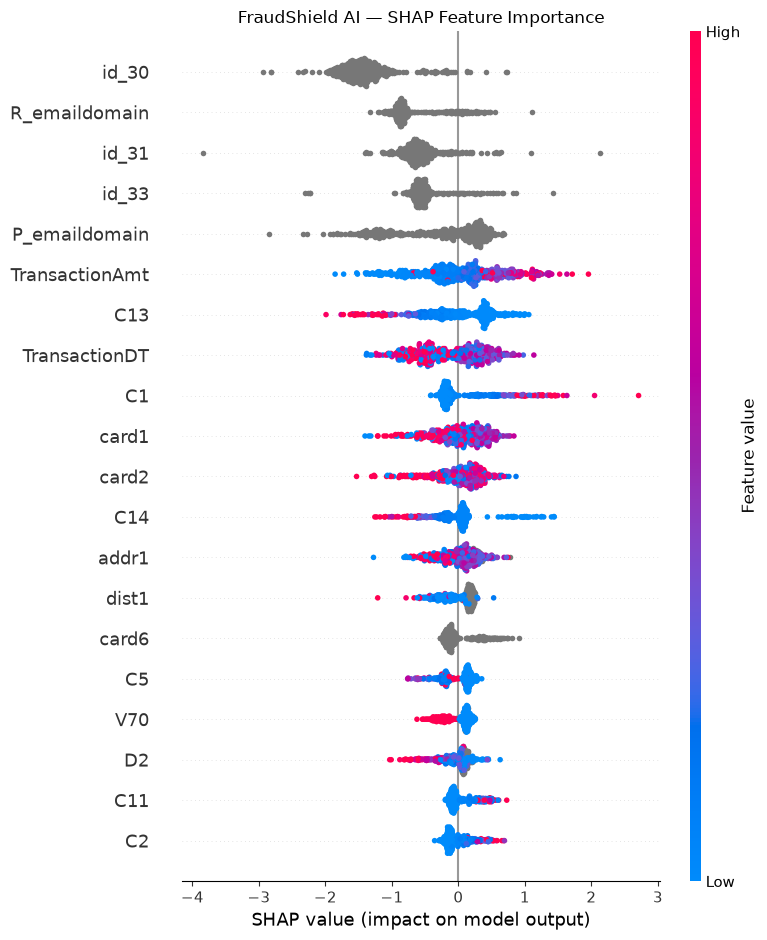

In [5]:

shap.summary_plot(
    fraud_shap_values,
    X_sample,
    max_display=20,
    show=False
)

plt.title("FraudShield AI — SHAP Feature Importance")
plt.tight_layout()

plt.savefig(
    REPORT_DIR / "shap_summary.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [6]:

# Calculate fraud probabilities for the SHAP sample.
sample_probabilities = model.predict_proba(X_sample)[:, 1]

# Select the transaction with the highest predicted fraud probability.
highest_risk_position = int(np.argmax(sample_probabilities))

transaction_to_explain = X_sample.iloc[[highest_risk_position]]
transaction_probability = float(
    sample_probabilities[highest_risk_position]
)

print(f"Predicted fraud probability: {transaction_probability:.2%}")
print("Actual fraud label:", int(
    sample_df.iloc[highest_risk_position]["isFraud"]
))

display(
    sample_df.iloc[[highest_risk_position]][
        ["TransactionID", "TransactionAmt", "ProductCD", "isFraud"]
    ]
)

Predicted fraud probability: 99.99%
Actual fraud label: 1


,TransactionID,TransactionAmt,ProductCD,isFraud
292032,3279032,450.0,H,1


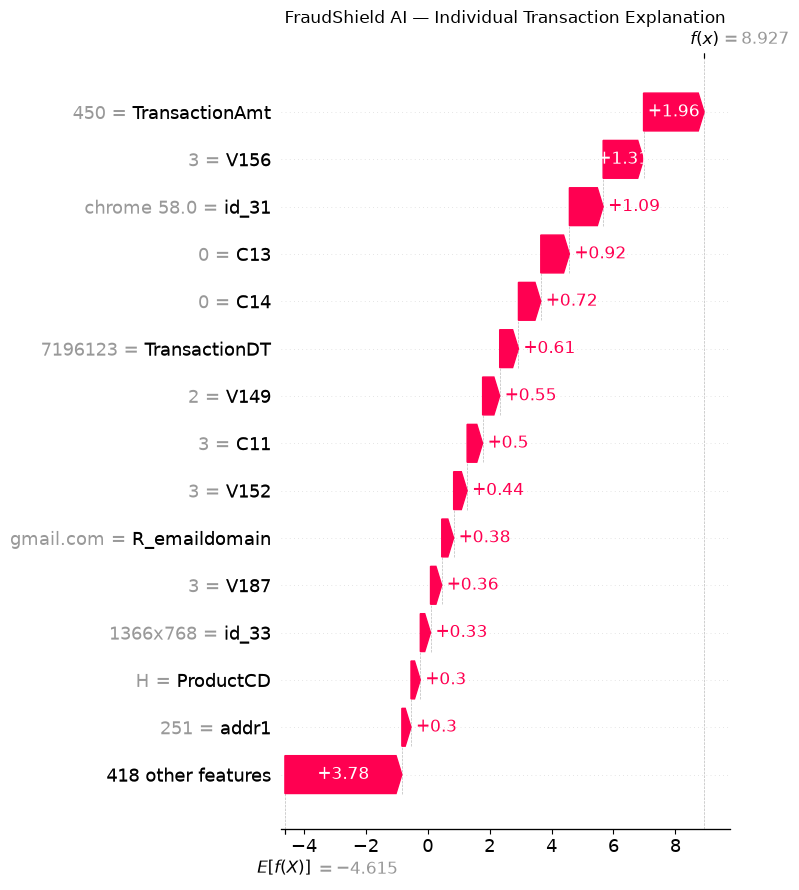

In [7]:

single_shap_values = np.asarray(fraud_shap_values)[
    highest_risk_position
]

explanation = shap.Explanation(
    values=single_shap_values,
    base_values=explainer.expected_value[1]
    if isinstance(explainer.expected_value, (list, np.ndarray))
    else explainer.expected_value,
    data=transaction_to_explain.iloc[0].to_numpy(),
    feature_names=feature_columns,
)

shap.plots.waterfall(explanation, max_display=15, show=False)
plt.title("FraudShield AI — Individual Transaction Explanation")
plt.tight_layout()

plt.savefig(
    REPORT_DIR / "individual_transaction_shap.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()

In [8]:

global_importance = pd.DataFrame({
    "feature": feature_columns,
    "mean_absolute_shap": np.abs(fraud_shap_values).mean(axis=0),
}).sort_values("mean_absolute_shap", ascending=False)

display(global_importance.head(25))

global_importance.to_csv(
    REPORT_DIR / "shap_global_importance.csv",
    index=False,
)

print("Global SHAP importance saved.")
print("Individual explanation saved to reports/individual_transaction_shap.png")

,feature,mean_absolute_shap
421,id_30,1.425172
14,R_emaildomain,0.746627
422,id_31,0.611830
424,id_33,0.563904
13,P_emaildomain,0.525054
1,TransactionAmt,0.493984
27,C13,0.447428
0,TransactionDT,0.431312
15,C1,0.325818
3,card1,0.298545


Global SHAP importance saved.
Individual explanation saved to reports/individual_transaction_shap.png
